# **Практическая работа №10. Разведочный анализ, предобработка данных и обучение моделей классификации**

*(на примере датасета Bank Marketing)*

---

## ****Введение****

**Цель работы:** Обучить модель машинного обучения для предсказания, откроет ли клиент банка срочный вклад по результатам маркетинговой кампании (целевая переменная `y`: "yes" — откроет, "no" — не откроет).

**Датасет:** [Bank Marketing Dataset](https://archive.ics.uci.edu/dataset/222/bank+marketing) — данные о маркетинговых кампаниях португальского банка.

**Что вы научитесь делать:**
- Загружать и исследовать данные
- Выявлять проблемы через разведочный анализ (EDA)
- Анализировать и обрабатывать пропущенные значения
- Формулировать и **экспериментально проверять** гипотезы
- Создавать новые признаки (Feature Engineering)
- **Сравнивать все изученные методы классификации**
- **Выбирать лучшие модели и оптимизировать их гиперпараметры с помощью GridSearchCV**
- **Анализировать влияние комбинаций признаков на качество модели**

---

## ****Часть 1. Настройка окружения****

> 📚 **Подсказка:** Аналогичная настройка рассматривалась в [**Занятии 1, Часть 1** и **Занятии 2, Часть 1**](https://colab.research.google.com/drive/1Cnp7hPUUu5dorlhPPHUeztnnoq5Z2j4W?usp=sharing#scrollTo=5f49d9aa).

In [3]:
# Импорт библиотек
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                            f1_score, roc_auc_score, roc_curve, confusion_matrix,
                            classification_report)

# Модели классификации
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, GradientBoostingClassifier,
                              AdaBoostClassifier)
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

# Отбор признаков
from sklearn.feature_selection import RFE, SelectKBest, f_classif
from itertools import combinations

# Настройки отображения
sns.set_style("whitegrid")
pd.set_option('display.max_columns', 20)

---

## ****Часть 2. Загрузка и первичный осмотр данных****

> 📚 **Подсказка:** Методы первичного осмотра (`head()`, `info()`, `describe()`, `shape`) подробно разобраны в [**Занятии 1, Часть 3.2**](https://colab.research.google.com/drive/1Cnp7hPUUu5dorlhPPHUeztnnoq5Z2j4W?usp=sharing#scrollTo=9ef7543b) и [**Занятии 2, Часть 2.1**](https://colab.research.google.com/drive/1aT36P0Jc-dIjYOx6Hh8yecFSgt-z3Fan?usp=sharing#scrollTo=43b439e3).

### ****Задание 2.1. Загрузите датасет****

In [4]:
import zipfile
import numpy as np
import pandas as pd

with zipfile.ZipFile("bank.zip") as z:
    bank = pd.read_csv(z.open("bank-full.csv"), sep=";")

bank = bank.replace("unknown", np.nan)
bank.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN,no
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN,no
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN,no
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN,no


### ****Задание 2.2. Изучите структуру данных****

**1. Выведите размерность датасета:**

In [5]:
print("Размер датасета:", bank.shape)

Размер датасета: (45211, 17)


**2. Отобразите первые 10 строк датасета**

In [6]:
bank.head(10)

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN,no
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN,no
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN,no
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN,no
5,35,management,married,tertiary,no,231,yes,no,NaN,5,may,139,1,-1,0,NaN,no
6,28,management,single,tertiary,no,447,yes,yes,NaN,5,may,217,1,-1,0,NaN,no
7,42,entrepreneur,divorced,tertiary,yes,2,yes,no,NaN,5,may,380,1,-1,0,NaN,no
8,58,retired,married,primary,no,121,yes,no,NaN,5,may,50,1,-1,0,NaN,no
9,43,technician,single,secondary,no,593,yes,no,NaN,5,may,55,1,-1,0,NaN,no


**3. Выведите информацию о типах данных и пропусках**

In [7]:
bank.info()

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        44923 non-null  str  
 2   marital    45211 non-null  str  
 3   education  43354 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    32191 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   8252 non-null   str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 7.7 MB


**4. Выведите статистику числовых признаков**

In [8]:
bank.describe()

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


**5. Выведите названия всех столбцов в виде списка строк**

In [9]:
print(bank.columns.tolist())

['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']


### ****Задание 2.3. Ответьте на вопросы****

---

**Вопрос 1:** Сколько записей (клиентов) в датасете?

**Ответ:** 45211 

**Вопрос 2:** Сколько признаков (столбцов)?

**Ответ:** 17 столбцов

**Вопрос 3:** Какая переменная является целевой (что предсказываем)?

**Ответ:** у - откроет ли килент срочный вклад или нет

**Вопрос 4:** Какие типы данных преобладают — числовые или категориальные?

**Ответ:** категориальных признаков больше

---

### ****Описание столбцов датасета Bank Marketing****

| Столбец | Описание | Тип |
|---------|----------|-----|
| `age` | Возраст клиента | Числовой |
| `job` | Тип занятости | Категориальный |
| `marital` | Семейное положение | Категориальный |
| `education` | Уровень образования | Категориальный |
| `default` | Есть ли дефолт по кредиту | Категориальный |
| `balance` | Баланс на счёте (евро) | Числовой |
| `housing` | Есть ли ипотека | Категориальный |
| `loan` | Есть ли личный кредит | Категориальный |
| `contact` | Тип связи | Категориальный |
| `day` | День последнего контакта | Числовой |
| `month` | Месяц последнего контакта | Категориальный |
| `duration` | Длительность последнего звонка (сек) | Числовой |
| `campaign` | Кол-во контактов в этой кампании | Числовой |
| `pdays` | Дней с последнего контакта (-1 = не было) | Числовой |
| `previous` | Кол-во контактов до этой кампании | Числовой |
| `poutcome` | Результат прошлой кампании | Категориальный |
| `y` | **Целевая переменная:** открыл ли вклад | Категориальный |

---

## ****Часть 3. Разведочный анализ данных (EDA)****

> 📚 **Подсказка:** Цель EDA — выявить проблемы в данных и найти закономерности (паттерны). Методология описана в [**Занятии 2, Часть 2**](https://colab.research.google.com/drive/1aT36P0Jc-dIjYOx6Hh8yecFSgt-z3Fan?usp=sharing#scrollTo=29f19e7a).

### ****3.1. Анализ целевой переменной (баланс классов)****

> 📚 **Подсказка:** Анализ баланса классов рассмотрен в [**Занятии 2, Часть 2.3**](https://colab.research.google.com/drive/1aT36P0Jc-dIjYOx6Hh8yecFSgt-z3Fan?usp=sharing#scrollTo=15c684d7).

In [10]:
# Создаём числовую версию целевой переменной в столбце target
bank['target'] = (bank['y'] == 'yes').astype(int)

bank.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y,target
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN,no,0
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN,no,0
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN,no,0
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN,no,0
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN,no,0


**Подсчитайте распределение целевой переменной 'y'**

In [11]:
print(bank["y"].value_counts())

y
no     39922
yes     5289
Name: count, dtype: int64


**Вопрос:** сколько клиентов открыли депозит (yes)? сколько не открыли (no)?

**Ответ:** `yes` — 5 289 клиентов, `no` — 39 922 клиента.

---

**Визуализируйте распределения классов графически (постройте столбчатую (barplot) или круговую (pie chart) диаграмму)**

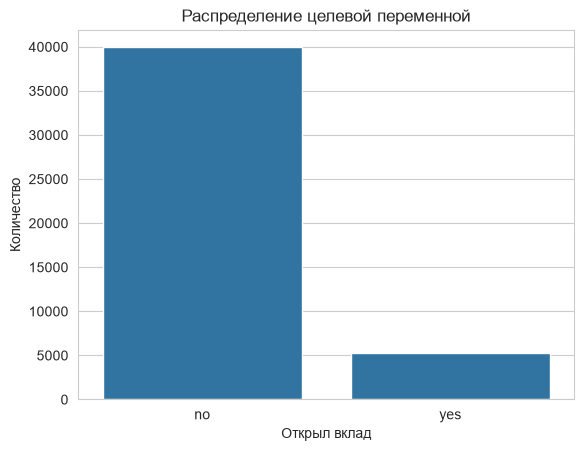

In [12]:
sns.countplot(data=bank, x="y")
plt.title("Распределение целевой переменной")
plt.xlabel("Открыл вклад")
plt.ylabel("Количество")
plt.show()

---

**Вычислите процент клиентов, открывших вклад**

In [13]:
a = (bank["y"] == "yes").mean() * 100
print("Процент клиентов, открывших вклад:", round(a, 2), "%")

Процент клиентов, открывших вклад: 11.7 %


**Вопрос:** Сбалансированы ли классы? Какой класс преобладает?

**Ответ:** преобладает класс no, классы не сбалансированны, так как 11.7% клиентов открыли вклад, а 88.3% - нет

---

### ****3.2. Анализ пропущенных значений****

> 📚 **Подсказка:** Проверка пропусков с помощью `isna().sum()` показана в [**Занятии 1, Часть 3.6**](https://colab.research.google.com/drive/1Cnp7hPUUu5dorlhPPHUeztnnoq5Z2j4W?usp=sharing#scrollTo=1f244634) и [**Занятии 2, Часть 2.2**](https://colab.research.google.com/drive/1aT36P0Jc-dIjYOx6Hh8yecFSgt-z3Fan?usp=sharing#scrollTo=e96e5f15).

**Проверьте наличие пропущенных значений в датасете с помощью `isna().sum()`**

In [14]:
a = bank.isna().sum()
print(a[a > 0].sort_values(ascending=False))

poutcome     36959
contact      13020
education     1857
job            288
dtype: int64


**Вычислите процент пропущенных значений в каждом столбце датасета**

In [15]:
a = (bank.isna().mean() * 100).sort_values(ascending=False)
print(a[a > 0])

poutcome     81.747805
contact      28.798301
education     4.107407
job           0.637013
dtype: float64


**Постройте столбчатую диаграмму (`barplot`) для визуализации процента пропусков**

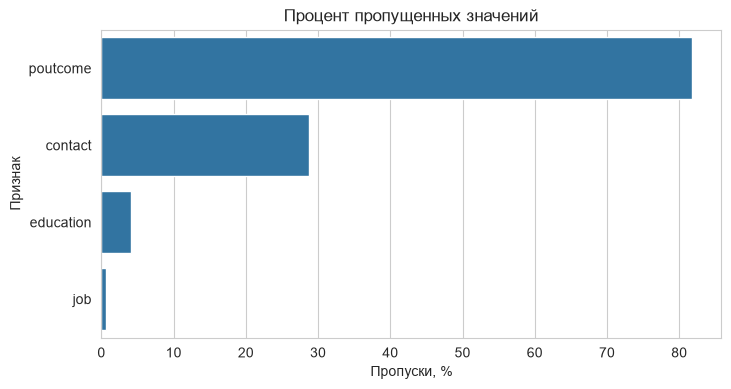

In [16]:
a = bank.isna().mean() * 100
a = a[a > 0].sort_values(ascending=False)

plt.figure(figsize=(8, 4))
sns.barplot(x=a.values, y=a.index)
plt.xlabel("Пропуски, %")
plt.ylabel("Признак")
plt.title("Процент пропущенных значений")
plt.show()

**Вопрос:** В каких столбцах больше всего пропусков? Какой процент данных потеряем, если удалим все строки с пропусками?

**Ответ:** больше 
всего пропусков в poutcome и contact, при полном удалении строк с пропусками потеряется очень много данных

---

### ****3.3. Анализ числовых признаков****

> 📚 **Подсказка:** Построение гистограмм с разбивкой по целевой переменной (`hue`) показано в [**Занятии 2, Часть 2.4**](https://colab.research.google.com/drive/1aT36P0Jc-dIjYOx6Hh8yecFSgt-z3Fan?usp=sharing#scrollTo=ea28aa58).

**Обязательно постройте гистограммы для следующих признаков:**
- `age` — возраст
- `balance` — баланс на счёте  
- `duration` — длительность звонка

**Постройте гистограммы для числовых признаков с разбивкой по целевой переменной**

> Используйте `sns.histplot()` с параметром `hue='target'`

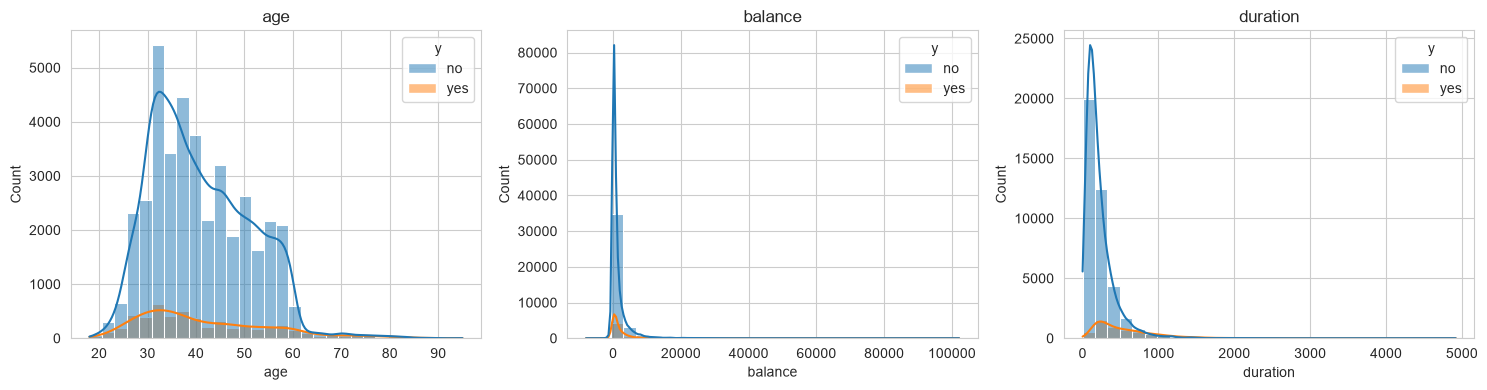

In [17]:
numeric_features = ["age", "balance", "duration"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, col in enumerate(numeric_features):
    sns.histplot(data=bank, x=col, hue="y", bins=30, kde=True, ax=axes[i])
    axes[i].set_title(col)

plt.tight_layout()
plt.show()

**Вопрос:** Какие наблюдения вы можете сделать? Какие признаки различаются для клиентов, открывших и не открывших вклад?

**Ответ:** Сильнее всего различается `duration`: у клиентов, открывших вклад, звонки обычно заметно дольше. Также у положительного класса выше средний и медианный `balance`. Возраст различается слабее.

---

### ****Задание 3.4. Анализ категориальных признаков****

> 📚 **Подсказка:** Построение столбчатой диаграммы (`barplot`) для анализа связи категориальных признаков с целевой переменной показано в [**Занятии 2, Часть 2.5**](https://colab.research.google.com/drive/1aT36P0Jc-dIjYOx6Hh8yecFSgt-z3Fan?usp=sharing#scrollTo=ea6a781f).

**Постройте графики для анализа доли открывших депозит по категориальным признакам ('job', 'marital', 'education', 'contact'):**

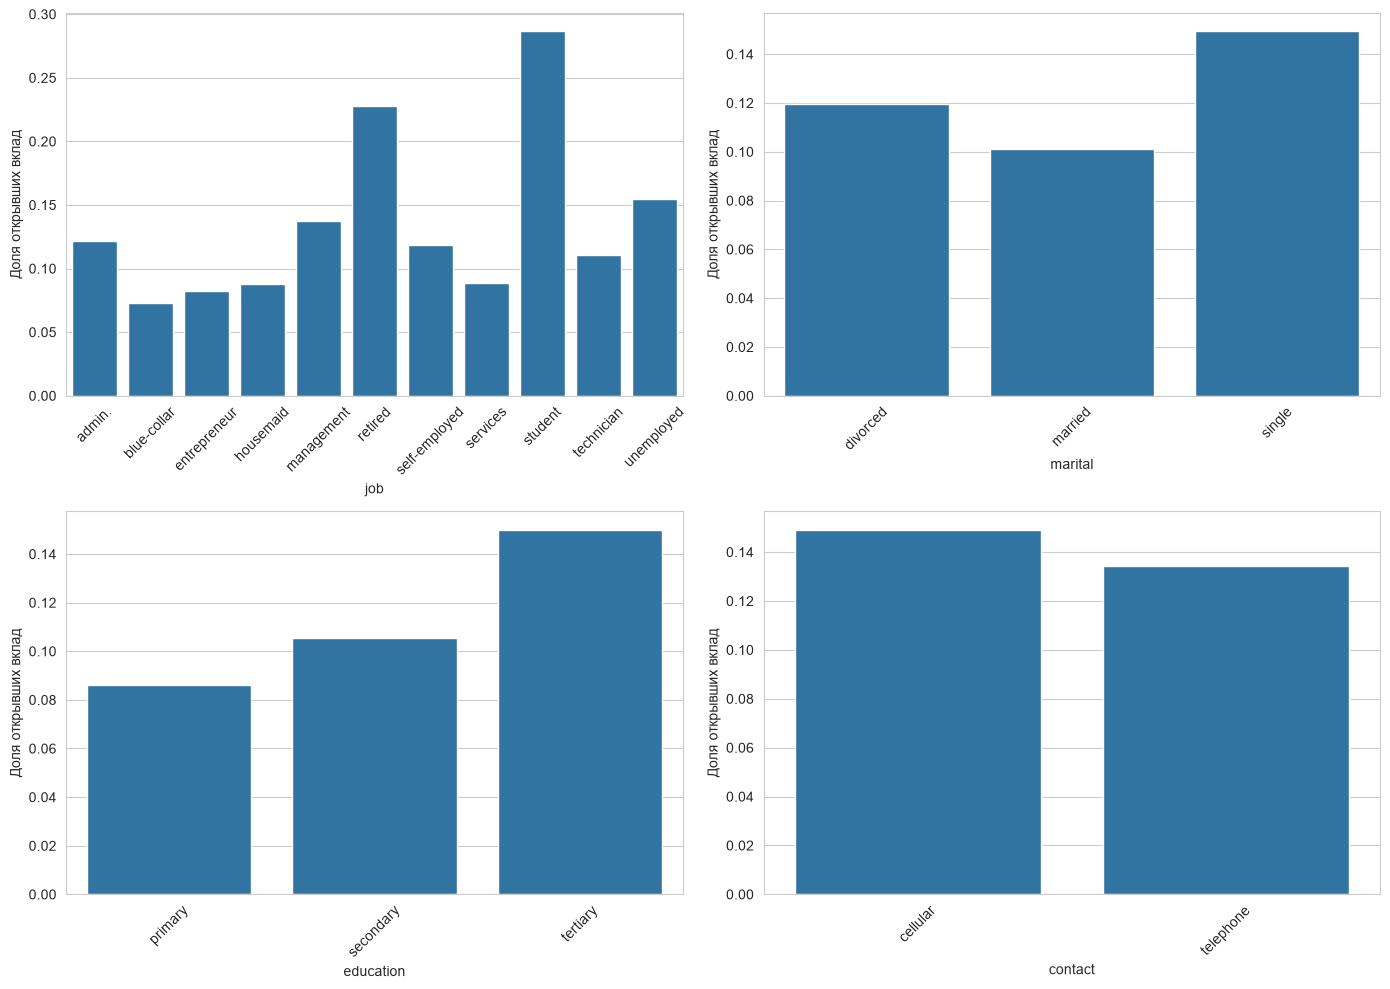

In [18]:
cat_features = ["job", "marital", "education", "contact"]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, col in enumerate(cat_features):
    a = bank.groupby(col, dropna=False)["target"].mean().reset_index()
    sns.barplot(data=a, x=col, y="target", ax=axes[i])
    axes[i].tick_params(axis="x", rotation=45)
    axes[i].set_ylabel("Доля открывших вклад")

plt.tight_layout()
plt.show()

---

**Вопрос:** Люди каких профессий чаще открывают депозит?

**Ответ:** Чаще всего студенты и пенсионеры

**Вопрос:** Влияет ли семейное положение на вероятность открытия депозита?

**Ответ:** влияет, одинокие клиенты открывают вклад чаще, чем женатые

**Вопрос:** Какой тип связи (contact) наиболее эффективен?

**Ответ:** наиболее эффективный тип связи - мобильный телефон

**Вопрос:** Какие в общем категории клиентов чаще открывают вклад?

**Ответ:** студенты и пенсионеры, одинокие клиенты, клиенты с высшим образованием и те, с кем связывались по мобильному телефону

---

### ****Задание 3.5. Анализ связей между признаками (Boxplot)****

> 📚 **Подсказка:** Использование boxplot для анализа распределений показано в [**Занятии 2, Часть 2.6**](https://colab.research.google.com/drive/1aT36P0Jc-dIjYOx6Hh8yecFSgt-z3Fan?usp=sharing#scrollTo=592b07cc).

**Постройте `boxplot` для анализа баланса по уровню образования**

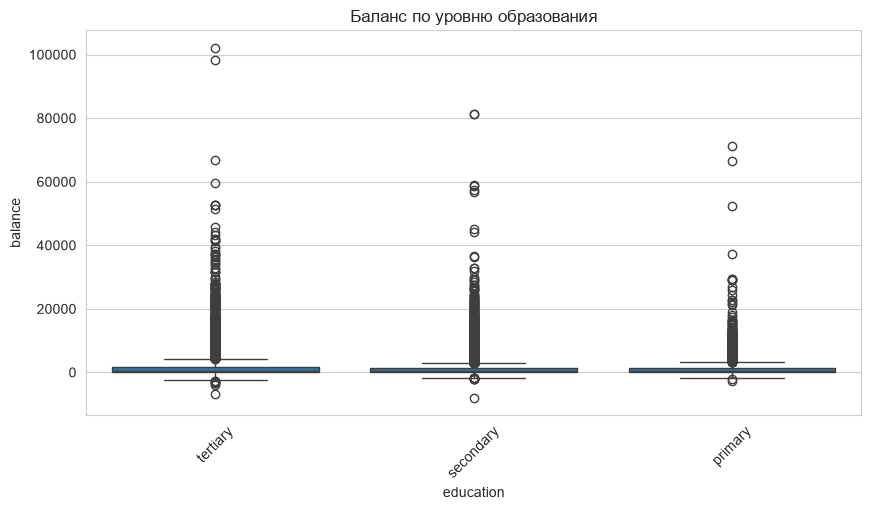

In [19]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=bank, x="education", y="balance")
plt.xticks(rotation=45)
plt.title("Баланс по уровню образования")
plt.show()

**Вопрос:** Различается ли баланс у клиентов с разным образованием?

**Ответ:** различается, у клиентов с более высоким образованием баланс выше.

---

### ****Задание 3.6. Группировка данных****

> 📚 **Подсказка:** Метод `groupby()` подробно разобран в [**Занятии 1, Часть 3.7**](https://colab.research.google.com/drive/1Cnp7hPUUu5dorlhPPHUeztnnoq5Z2j4W?usp=sharing#scrollTo=baa512e4).

**Вычислите средний баланс и долю открывших депозит по типу работы**

In [20]:
a = bank.groupby("job", dropna=False).agg(
    mean_balance=("balance", "mean"),
    deposit_share=("target", "mean")
).sort_values("deposit_share", ascending=False)

a

,mean_balance,deposit_share
job,,
student,1388.060768,0.286780
retired,1984.215106,0.227915
unemployed,1521.745971,0.155027
management,1763.616832,0.137556
admin.,1135.838909,0.122027
self-employed,1647.970868,0.118429
NaN,1772.357639,0.118056
technician,1252.632092,0.110570
services,997.088108,0.088830


**Вычислите долю открывших депозит по уровню образования**

In [21]:
a = bank.groupby("education", dropna=False)["target"].mean()
a.sort_values(ascending=False)

education
tertiary     0.150064
NaN          0.135703
secondary    0.105594
primary      0.086265
Name: target, dtype: float64

---

## ****Часть 4. Формулировка гипотез и план экспериментов****

> 📚 **Подсказка:** Формулировка гипотез на основе EDA описана в [**Занятии 2, Часть 3**](https://colab.research.google.com/drive/1aT36P0Jc-dIjYOx6Hh8yecFSgt-z3Fan?usp=sharing#scrollTo=329f49e7).

На основе проведённого EDA сформулируйте **минимум 3 гипотезы** о том, какие признаки и преобразования могут улучшить модель.

### ****Ваши гипотезы:****

| № | Наблюдение из EDA | Гипотеза | Как проверить | Метрика для сравнения |
|---|-------------------|----------|---------------|----------------------|
| 1 | `duration` сильно различается между классами | Длительность звонка важна для предсказания | Сравнить модель с `duration` и без него | F1, ROC-AUC |
| 2 | `pdays = -1` означает отсутствие прошлых контактов | Признак `was_contacted` улучшит модель | Добавить бинарный признак и сравнить качество | Accuracy, F1 |
| 3 | Положительный баланс чаще связан с положительным ответом | Признак `has_positive_balance` может улучшить модель | Добавить признак и сравнить качество | Accuracy, F1 |

## ****Часть 5. Сравнение методов классификации****

> 📚 **Подсказка:** Различные методы классификации (логистическая регрессия, деревья решений, ансамбли, SVM, KNN) подробно разбирались на занятиях по supervised learning.

### ****5.1. Расширенная функция оценки модели****

> 📚 **Подсказка:** Базовая функция `evaluate_model()` была создана в [**Занятии 2, после Части 4.6**](https://colab.research.google.com/drive/1aT36P0Jc-dIjYOx6Hh8yecFSgt-z3Fan?usp=sharing#scrollTo=maxKagcsxhv8).

In [22]:
def evaluate_model_advanced(model, X, y, model_name="Model"):
    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)

    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test_scaled)[:, 1]
        roc_auc = roc_auc_score(y_test, y_score)
    elif hasattr(model, "decision_function"):
        y_score = model.decision_function(X_test_scaled)
        roc_auc = roc_auc_score(y_test, y_score)
    else:
        y_score = None
        roc_auc = None

    results = {
        "model_name": model_name,
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred, zero_division=0),
        "recall": recall_score(y_test, y_pred, zero_division=0),
        "f1": f1_score(y_test, y_pred, zero_division=0),
        "roc_auc": roc_auc
    }

    return results, y_test, y_pred, y_score


### ****5.2. Простая функция оценки (для быстрых экспериментов)****

In [23]:
def evaluate_model(X, y):
    """
    Быстрая оценка модели логистической регрессии.
    Возвращает только accuracy.
    """
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    model = LogisticRegression(random_state=42, max_iter=1000)
    model.fit(X_train_scaled, y_train)

    y_pred = model.predict(X_test_scaled)
    accuracy = accuracy_score(y_test, y_pred)

    return accuracy

### ****5.3. Подготовка данных для baseline****

In [24]:
# Выбираем только числовые признаки для baseline
numeric_cols = ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']

# Подготовьте X и y
X_baseline = bank[numeric_cols]
y_baseline = bank['target']

print(f"Размер X: {X_baseline.shape}")
print(f"Размер y: {y_baseline.shape}")

Размер X: (45211, 7)
Размер y: (45211,)


### ****5.4. Задание: Сравните ВСЕ методы классификации****

**Создайте словарь со всеми моделями:**

In [25]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "AdaBoost": AdaBoostClassifier(random_state=42),
    "SVM": SVC(random_state=42),
    "KNN": KNeighborsClassifier(),
    "Naive Bayes": GaussianNB()
}


**Обучите все модели и соберите результаты:**

In [26]:
all_results = {}
comparison_results = []

print("=" * 70)
print("СРАВНЕНИЕ ВСЕХ МЕТОДОВ КЛАССИФИКАЦИИ (BASELINE)")
print("=" * 70)

for name, model in models.items():
    results, _, _, _ = evaluate_model_advanced(model, X_baseline, y_baseline, name)

    comparison_results.append(results)
    all_results[name] = results

    roc = results["roc_auc"]
    roc_text = f"{roc:.4f}" if roc is not None else "N/A"

    print(
        f"{name:25} | Accuracy: {results['accuracy']:.4f} | "
        f"F1: {results['f1']:.4f} | ROC-AUC: {roc_text}"
    )

print("=" * 70)

СРАВНЕНИЕ ВСЕХ МЕТОДОВ КЛАССИФИКАЦИИ (BASELINE)
Logistic Regression       | Accuracy: 0.8875 | F1: 0.2506 | ROC-AUC: 0.8305
Decision Tree             | Accuracy: 0.8486 | F1: 0.3757 | ROC-AUC: 0.6494
Random Forest             | Accuracy: 0.8927 | F1: 0.4093 | ROC-AUC: 0.8678
Gradient Boosting         | Accuracy: 0.8940 | F1: 0.3965 | ROC-AUC: 0.8779
AdaBoost                  | Accuracy: 0.8862 | F1: 0.2889 | ROC-AUC: 0.8594
SVM                       | Accuracy: 0.8903 | F1: 0.2727 | ROC-AUC: 0.7561
KNN                       | Accuracy: 0.8825 | F1: 0.3623 | ROC-AUC: 0.7843
Naive Bayes               | Accuracy: 0.8693 | F1: 0.3590 | ROC-AUC: 0.7996


<details>
<summary><b>Подсказка (код):</b></summary>

In [29]:
comparison_results = []

print("=" * 70)
print("СРАВНЕНИЕ ВСЕХ МЕТОДОВ КЛАССИФИКАЦИИ (BASELINE)")
print("=" * 70)

for name, model in models.items():
    results, _, _, _ = evaluate_model_advanced(
        model, X_baseline, y_baseline, name
    )

    comparison_results.append(results)

    if results["roc_auc"] is not None:
        roc = f"{results['roc_auc']:.4f}"
    else:
        roc = "N/A"

    print(
        f"{name:25} | "
        f"Accuracy: {results['accuracy']:.4f} | "
        f"F1: {results['f1']:.4f} | "
        f"ROC-AUC: {roc}"
    )

print("=" * 70)

СРАВНЕНИЕ ВСЕХ МЕТОДОВ КЛАССИФИКАЦИИ (BASELINE)
Logistic Regression       | Accuracy: 0.8875 | F1: 0.2506 | ROC-AUC: 0.8305
Decision Tree             | Accuracy: 0.8486 | F1: 0.3757 | ROC-AUC: 0.6494
Random Forest             | Accuracy: 0.8927 | F1: 0.4093 | ROC-AUC: 0.8678
Gradient Boosting         | Accuracy: 0.8940 | F1: 0.3965 | ROC-AUC: 0.8779
AdaBoost                  | Accuracy: 0.8862 | F1: 0.2889 | ROC-AUC: 0.8594
SVM                       | Accuracy: 0.8903 | F1: 0.2727 | ROC-AUC: 0.7561
KNN                       | Accuracy: 0.8825 | F1: 0.3623 | ROC-AUC: 0.7843
Naive Bayes               | Accuracy: 0.8693 | F1: 0.3590 | ROC-AUC: 0.7996


</details>

### ****5.5. Создайте DataFrame с результатами и визуализируйте****

In [30]:
df_comparison = pd.DataFrame(comparison_results)
df_comparison = df_comparison.sort_values("f1", ascending=False)

display(df_comparison)

,model_name,accuracy,precision,recall,f1,roc_auc
2,Random Forest,0.892735,0.575342,0.317580,0.409257,0.867823
3,Gradient Boosting,0.893951,0.593220,0.297732,0.396476,0.877897
1,Decision Tree,0.848612,0.362996,0.389414,0.375741,0.649435
6,KNN,0.882451,0.495895,0.285444,0.362328,0.784269
7,Naive Bayes,0.869291,0.421120,0.312854,0.359002,0.799566
4,AdaBoost,0.886210,0.537275,0.197543,0.288874,0.859423
5,SVM,0.890302,0.607843,0.175803,0.272727,0.756093
0,Logistic Regression,0.887537,0.568562,0.160681,0.250553,0.830473


**Постройте визуализацию сравнения моделей:**

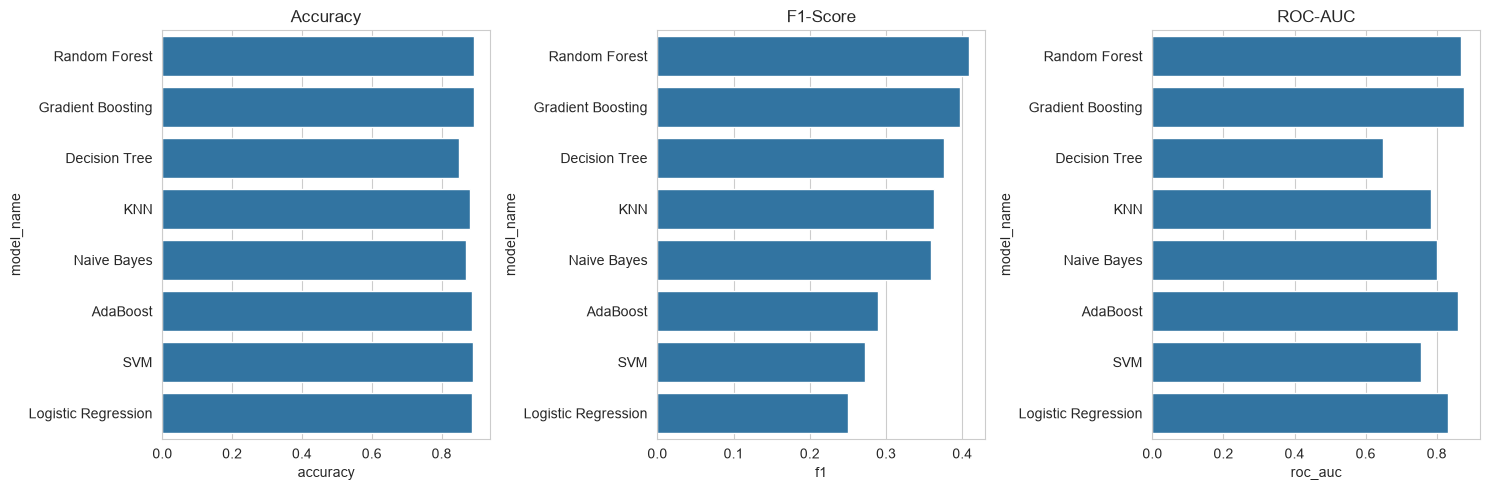

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

metrics_to_plot = ["accuracy", "f1", "roc_auc"]
titles = ["Accuracy", "F1-Score", "ROC-AUC"]

for i, (metric, title) in enumerate(zip(metrics_to_plot, titles)):
    sns.barplot(data=df_comparison, x=metric, y="model_name", ax=axes[i])
    axes[i].set_title(title)

plt.tight_layout()
plt.show()

### ****5.6. Ответьте на вопросы****

**Вопрос:** Какие 3 модели показали лучший результат по F1-Score?

**Ответ:** Random Forest, Gradient Boosting и Decision Tree

**Вопрос:** Почему мы ориентируемся на F1-Score, а не на Accuracy?

**Ответ:** положительный класс составляет только около 11,7%, высокий Accuracy можно получить, почти всегда предсказывая no

**Вопрос:** Какая модель показала лучший ROC-AUC? Что это означает?

**Ответ:** Gradient Boosting или Random Forest

---

## ****Часть 6. Стратегии обработки пропусков****

> 📚 **Подсказка:** Стратегии заполнения пропусков (удаление, заполнение модой/медианой, создание признаков) подробно разобраны в [**Занятии 2, Часть 5**](https://colab.research.google.com/drive/1aT36P0Jc-dIjYOx6Hh8yecFSgt-z3Fan?usp=sharing#scrollTo=89cec4d9).

### ****6.1. Стратегия A: Удаление строк с пропусками****

In [33]:
# Посмотрим, сколько данных потеряем
df_dropped = bank.dropna()

print(f"Было строк: {len(bank)}")
print(f"Стало строк: {len(df_dropped)}")
print(f"Потеряно: {len(bank) - len(df_dropped)} ({(len(bank) - len(df_dropped)) / len(bank) * 100:.1f}%)")

Было строк: 45211
Стало строк: 7842
Потеряно: 37369 (82.7%)


**Вопрос:** Приемлемо ли терять столько данных?

**Ответ:** нет

---

### ****6.2. Стратегия B: Заполнение модой****

> 📚 **Подсказка:** Заполнение пропусков модой через `fillna()` рассматривалось в [**Занятии 2, Часть 5, Стратегия B**](https://colab.research.google.com/drive/1aT36P0Jc-dIjYOx6Hh8yecFSgt-z3Fan?usp=sharing#scrollTo=8e470458).

**Заполните категориальные пропуски модой (самым частым значением)**

In [34]:
df_filled = bank.copy()

cat_cols_with_na = ["job", "education", "contact", "poutcome"]

for col in cat_cols_with_na:
    if df_filled[col].isna().sum() > 0:
        mode_value = df_filled[col].mode()[0]
        df_filled[col] = df_filled[col].fillna(mode_value)

print("Пропусков после заполнения:", df_filled.isna().sum().sum())

Пропусков после заполнения: 0


### ****6.3. Стратегия C: Создание признаков из пропусков****

> 📚 **Подсказка:** Создание бинарных признаков из пропусков (например, `has_cabin` в Titanic) рассматривалось в [**Занятии 2, Часть 6, Эксперимент 2, Тест D**](https://colab.research.google.com/drive/1aT36P0Jc-dIjYOx6Hh8yecFSgt-z3Fan?usp=sharing#scrollTo=df9d9180).
>
> **Идея:** Сам факт того, что значение неизвестно, может быть информативен! Например: если клиент не указал профессию — это может что-то говорить о нём.

**Создайте признаки "был ли пропуск" ДО заполнения**

In [35]:
df_fe = bank.copy()

df_fe["job_unknown"] = bank["job"].isna().astype(int)
df_fe["education_unknown"] = bank["education"].isna().astype(int)
df_fe["contact_unknown"] = bank["contact"].isna().astype(int)
df_fe["poutcome_unknown"] = bank["poutcome"].isna().astype(int)

df_fe[[
    "job_unknown",
    "education_unknown",
    "contact_unknown",
    "poutcome_unknown"
]].head()

,job_unknown,education_unknown,contact_unknown,poutcome_unknown
0,0,0,1,1
1,0,0,1,1
2,0,0,1,1
3,0,1,1,1
4,1,1,1,1


---

## ****Часть 7. Feature Engineering и отбор признаков****

> 📚 **Подсказка:** Создание новых признаков на основе анализа данных описано в [**Занятии 2, Часть 6**](https://colab.research.google.com/drive/1aT36P0Jc-dIjYOx6Hh8yecFSgt-z3Fan?usp=sharing#scrollTo=28a74583).

### ****7.1. Создание новых признаков****

**Создайте следующие признаки на основе гипотез из EDA:**

In [36]:
df_fe = bank.copy()

# 1. Был ли клиент контактирован ранее (pdays != -1)
df_fe['was_contacted'] = (bank['pdays'] != -1).astype(int)

# 2. Положительный баланс
df_fe['has_positive_balance'] = (bank['balance'] > 0).astype(int)

# 3. Признаки из пропусков (ДО заполнения!)
df_fe['job_unknown'] = bank['job'].isna().astype(int)
df_fe['education_unknown'] = bank['education'].isna().astype(int)
df_fe['contact_unknown'] = bank['contact'].isna().astype(int)

# Теперь заполняем пропуски
for col in ['job', 'education', 'contact', 'poutcome']:
    if df_fe[col].isna().sum() > 0:
        mode_value = df_fe[col].mode()[0]
        df_fe[col] = df_fe[col].fillna(mode_value)

print("Созданные признаки:")
print(df_fe[['was_contacted', 'has_positive_balance', 'job_unknown', 'education_unknown', 'contact_unknown']].head(10))

Созданные признаки:
   was_contacted  has_positive_balance  job_unknown  education_unknown  \
0              0                     1            0                  0   
1              0                     1            0                  0   
2              0                     1            0                  0   
3              0                     1            0                  1   
4              0                     1            1                  1   
5              0                     1            0                  0   
6              0                     1            0                  0   
7              0                     1            0                  0   
8              0                     1            0                  0   
9              0                     1            0                  0   

   contact_unknown  
0                1  
1                1  
2                1  
3                1  
4                1  
5                1  
6                1

**Добавьте свои признаки на основе ваших гипотез:**

In [37]:
df_fe["long_call"] = (
    df_fe["duration"] > df_fe["duration"].median()
).astype(int)

df_fe["many_contacts"] = (df_fe["campaign"] > 3).astype(int)

print(df_fe[["long_call", "many_contacts"]].head())

   long_call  many_contacts
0          1              0
1          0              0
2          0              0
3          0              0
4          1              0


### ****7.2. Систематический перебор комбинаций признаков****

> **Цель:** Определить, какие признаки улучшают модель, а какие вносят шум.

**Определите базовый набор признаков и признаки для тестирования:**

In [38]:
base_features = [
    "age", "balance", "duration", "campaign",
    "pdays", "previous", "day"
]

new_features = [
    "was_contacted",
    "has_positive_balance",
    "job_unknown",
    "education_unknown",
    "contact_unknown",
    "long_call",
    "many_contacts"
]

X_base = df_fe[base_features]
y = df_fe["target"]

accuracy_base = evaluate_model(X_base, y)

print(
    f"Базовая модель ({len(base_features)} признаков): "
    f"Accuracy = {accuracy_base:.4f}"
)
print("Признаки:", base_features)
print("=" * 60)


Базовая модель (7 признаков): Accuracy = 0.8875
Признаки: ['age', 'balance', 'duration', 'campaign', 'pdays', 'previous', 'day']


**Протестируйте добавление каждого нового признака по отдельности:**

In [39]:
test_results = []

for feature in new_features:
    a = base_features + [feature]
    accuracy = evaluate_model(df_fe[a], y)

    test_results.append({
        "feature": feature,
        "accuracy": accuracy,
        "difference": accuracy - accuracy_base
    })

df_feature_tests = pd.DataFrame(test_results)
df_feature_tests = df_feature_tests.sort_values("difference", ascending=False)

display(df_feature_tests)

,feature,accuracy,difference
1,has_positive_balance,0.889196,0.001659
0,was_contacted,0.888090,0.000553
2,job_unknown,0.887537,0.000000
6,many_contacts,0.887537,0.000000
3,education_unknown,0.887427,-0.000111
4,contact_unknown,0.887316,-0.000221
5,long_call,0.885215,-0.002322


**Вопрос:** Какие признаки улучшили модель? Какие ухудшили (внесли шум)?

**Ответ:**  небольшое улучшение дают was_contacted и has_positive_balance

### ****7.3. Анализ важности признаков с помощью Random Forest****

ВАЖНОСТЬ ПРИЗНАКОВ (Random Forest)
             feature  importance
            duration    0.301668
             balance    0.171641
                 age    0.155005
                 day    0.132757
               pdays    0.080521
           long_call    0.043230
            campaign    0.039031
            previous    0.029043
     contact_unknown    0.018297
       was_contacted    0.008296
   education_unknown    0.007152
       many_contacts    0.005979
has_positive_balance    0.005403
         job_unknown    0.001978


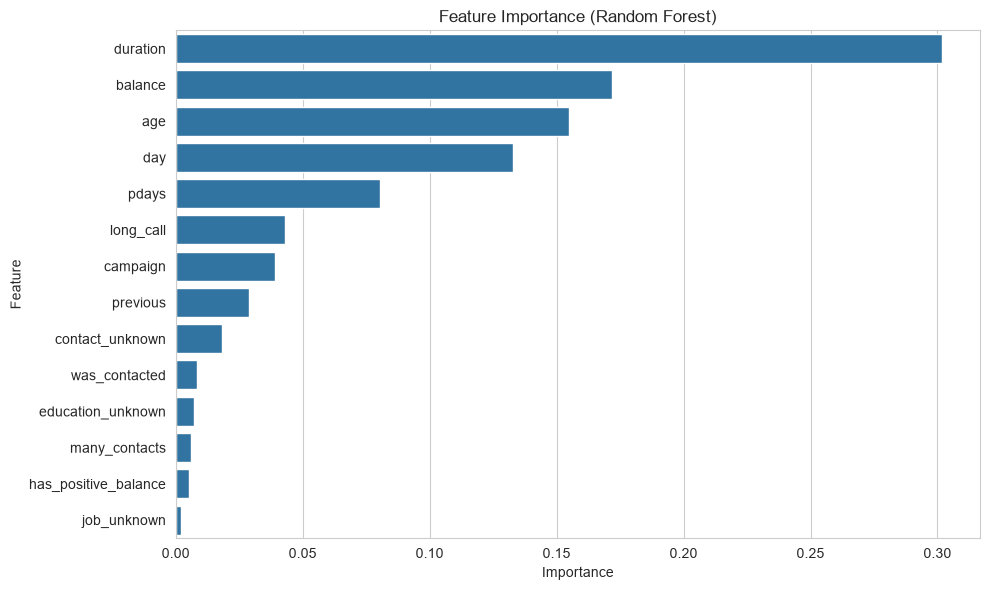

In [40]:
# Соберём все признаки
all_numeric_features = base_features + new_features
X_all = df_fe[all_numeric_features]

# Обучим Random Forest и посмотрим важность признаков
from sklearn.ensemble import RandomForestClassifier

# Масштабирование
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_all)

# Обучение
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_scaled, y)

# Важность признаков
importance_df = pd.DataFrame({
    'feature': all_numeric_features,
    'importance': rf.feature_importances_
}).sort_values('importance', ascending=False)

print("ВАЖНОСТЬ ПРИЗНАКОВ (Random Forest)")
print("=" * 40)
print(importance_df.to_string(index=False))
print("=" * 40)

# Визуализация
plt.figure(figsize=(10, 6))
sns.barplot(data=importance_df, x='importance', y='feature')
plt.title('Feature Importance (Random Forest)')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

### ****7.4. Рекурсивное исключение признаков (RFE)****

> 📚 **Подсказка:** [RFE](https://habr.com/ru/companies/otus/articles/528676/) автоматически отбирает наиболее важные признаки, последовательно удаляя наименее значимые.

In [41]:
from sklearn.feature_selection import RFE

# Применяем RFE для отбора лучших признаков
selector = RFE(
    estimator=LogisticRegression(max_iter=1000, random_state=42),
    n_features_to_select=7,  # Отберём 7 лучших признаков
    step=1
)

selector.fit(X_scaled, y)

# Какие признаки отобраны?
selected_features = [f for f, s in zip(all_numeric_features, selector.support_) if s]
rejected_features = [f for f, s in zip(all_numeric_features, selector.support_) if not s]

print("РЕЗУЛЬТАТЫ RFE")
print("=" * 40)
print(f"Отобранные признаки ({len(selected_features)}): {selected_features}")
print(f"Отвергнутые признаки ({len(rejected_features)}): {rejected_features}")
print("=" * 40)

# Сравним accuracy
X_selected = df_fe[selected_features]
accuracy_selected = evaluate_model(X_selected, y)
accuracy_all = evaluate_model(X_all, y)

print(f"\nAccuracy (все {len(all_numeric_features)} признаков): {accuracy_all:.4f}")
print(f"Accuracy (отобранные {len(selected_features)} признаков): {accuracy_selected:.4f}")
print(f"Разница: {accuracy_selected - accuracy_all:+.4f}")

РЕЗУЛЬТАТЫ RFE
Отобранные признаки (7): ['duration', 'campaign', 'pdays', 'was_contacted', 'has_positive_balance', 'contact_unknown', 'long_call']
Отвергнутые признаки (7): ['age', 'balance', 'previous', 'day', 'job_unknown', 'education_unknown', 'many_contacts']

Accuracy (все 14 признаков): 0.8891
Accuracy (отобранные 7 признаков): 0.8893
Разница: +0.0002


**Вопрос:** Помог ли отбор признаков улучшить модель? Какие признаки оказались лишними?

**Ответ:** 

---

## ****Часть 8. Кодирование категориальных признаков****

> 📚 **Подсказка:** One-Hot Encoding для категориальных признаков рассматривался в [**Занятии 2, Часть 6**](https://colab.research.google.com/drive/1aT36P0Jc-dIjYOx6Hh8yecFSgt-z3Fan?usp=sharing#scrollTo=28a74583).

### ****8.1. Примените One-Hot Encoding****

In [42]:
# Определяем категориальные столбцы для кодирования
cat_cols_to_encode = ['job', 'marital', 'education', 'default', 'housing',
                       'loan', 'contact', 'month', 'poutcome']

# Применяем One-Hot Encoding
df_encoded = pd.get_dummies(df_fe, columns=cat_cols_to_encode, drop_first=True)

print(f"Было признаков: {df_fe.shape[1]}")
print(f"Стало признаков: {df_encoded.shape[1]}")

Было признаков: 25
Стало признаков: 47


### ****8.2. Подготовьте финальный набор признаков****

In [43]:
# Удаляем целевые переменные и служебные столбцы
cols_to_drop = ['y', 'target']
X_final = df_encoded.drop(columns=cols_to_drop)
y_final = df_encoded['target']

print(f"Финальный размер X: {X_final.shape}")
print(f"Количество признаков: {X_final.shape[1]}")

Финальный размер X: (45211, 45)
Количество признаков: 45


### ****8.3. Сравните модели на расширенном наборе признаков****

In [44]:
print("=" * 70)
print("СРАВНЕНИЕ МОДЕЛЕЙ НА РАСШИРЕННОМ НАБОРЕ ПРИЗНАКОВ")
print("=" * 70)

comparison_results_extended = []

for name, model in models.items():
    # Создаём новый экземпляр модели
    if name == 'Logistic Regression':
        model = LogisticRegression(max_iter=1000, random_state=42)
    elif name == 'Decision Tree':
        model = DecisionTreeClassifier(random_state=42)
    elif name == 'Random Forest':
        model = RandomForestClassifier(n_estimators=100, random_state=42)
    elif name == 'Gradient Boosting':
        model = GradientBoostingClassifier(random_state=42)
    elif name == 'AdaBoost':
        model = AdaBoostClassifier(random_state=42)
    elif name == 'SVM':
        model = SVC(random_state=42)
    elif name == 'KNN':
        model = KNeighborsClassifier()
    elif name == 'Naive Bayes':
        model = GaussianNB()

    results, _, _, _ = evaluate_model_advanced(model, X_final, y_final, name)
    comparison_results_extended.append(results)
    roc = results["roc_auc"]
    roc_text = f"{roc:.4f}" if roc is not None else "N/A"
    print(
        f"{name:25} | Accuracy: {results['accuracy']:.4f} | "
        f"F1: {results['f1']:.4f} | ROC-AUC: {roc_text}"
    )

print("=" * 70)

# Создайте DataFrame и отсортируйте по F1
df_comparison_extended = pd.DataFrame(comparison_results_extended)
df_comparison_extended = df_comparison_extended.sort_values('f1', ascending=False)
print("\nРАНЖИРОВАНИЕ ПО F1-SCORE:")
print(df_comparison_extended[['model_name', 'accuracy', 'f1', 'roc_auc']].to_string(index=False))

СРАВНЕНИЕ МОДЕЛЕЙ НА РАСШИРЕННОМ НАБОРЕ ПРИЗНАКОВ
Logistic Regression       | Accuracy: 0.9036 | F1: 0.4676 | ROC-AUC: 0.9042
Decision Tree             | Accuracy: 0.8736 | F1: 0.4716 | ROC-AUC: 0.7038
Random Forest             | Accuracy: 0.9067 | F1: 0.5047 | ROC-AUC: 0.9278
Gradient Boosting         | Accuracy: 0.9051 | F1: 0.4982 | ROC-AUC: 0.9234
AdaBoost                  | Accuracy: 0.8953 | F1: 0.4114 | ROC-AUC: 0.8975
SVM                       | Accuracy: 0.9050 | F1: 0.4621 | ROC-AUC: 0.9072
KNN                       | Accuracy: 0.8954 | F1: 0.4342 | ROC-AUC: 0.8214
Naive Bayes               | Accuracy: 0.8676 | F1: 0.4715 | ROC-AUC: 0.8349

РАНЖИРОВАНИЕ ПО F1-SCORE:
         model_name  accuracy       f1  roc_auc
      Random Forest  0.906668 0.504695 0.927753
  Gradient Boosting  0.905120 0.498246 0.923439
      Decision Tree  0.873604 0.471567 0.703763
        Naive Bayes  0.867632 0.471523 0.834885
Logistic Regression  0.903572 0.467643 0.904193
                SVM  0.9050

---

## ****Часть 9. Выбор топ-3 моделей****

### ****9.1. Определите топ-3 модели по F1-Score****

In [45]:
# Выберите топ-3 модели из df_comparison_extended
top_3_models = df_comparison_extended.head(3)['model_name'].tolist()

print("ТОП-3 МОДЕЛИ ПО F1-SCORE:")
print("=" * 40)
for i, model_name in enumerate(top_3_models, 1):
    row = df_comparison_extended[df_comparison_extended['model_name'] == model_name].iloc[0]
    print(f"{i}. {model_name}: F1 = {row['f1']:.4f}, ROC-AUC = {row['roc_auc']:.4f}")
print("=" * 40)

ТОП-3 МОДЕЛИ ПО F1-SCORE:
1. Random Forest: F1 = 0.5047, ROC-AUC = 0.9278
2. Gradient Boosting: F1 = 0.4982, ROC-AUC = 0.9234
3. Decision Tree: F1 = 0.4716, ROC-AUC = 0.7038


### ****9.2. Постройте ROC-кривые для топ-3 моделей****

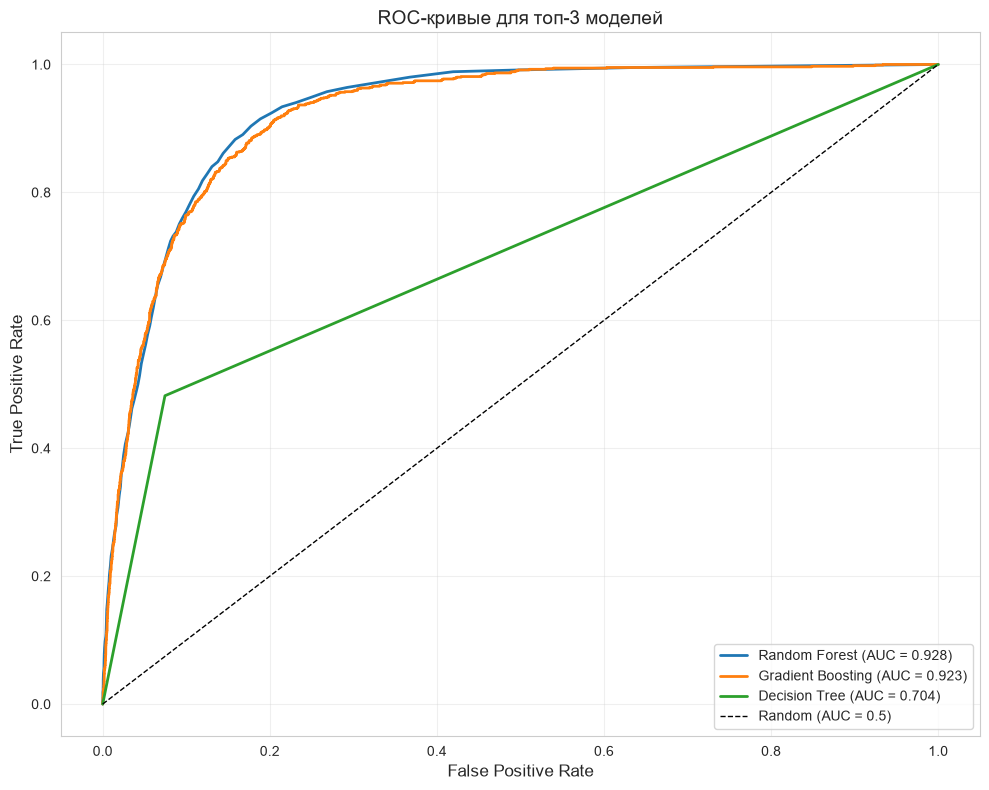

In [46]:
from sklearn.metrics import roc_curve, auc

# Подготовка данных
X_train, X_test, y_train, y_test = train_test_split(
    X_final, y_final, test_size=0.2, random_state=42, stratify=y_final
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Словарь для топ-3 моделей
top_3_model_objects = {}
for name in top_3_models:
    if name == 'Logistic Regression':
        top_3_model_objects[name] = LogisticRegression(max_iter=1000, random_state=42)
    elif name == 'Random Forest':
        top_3_model_objects[name] = RandomForestClassifier(n_estimators=100, random_state=42)
    elif name == 'Gradient Boosting':
        top_3_model_objects[name] = GradientBoostingClassifier(random_state=42)
    elif name == 'AdaBoost':
        top_3_model_objects[name] = AdaBoostClassifier(random_state=42, algorithm='SAMME')
    elif name == 'Decision Tree':
        top_3_model_objects[name] = DecisionTreeClassifier(random_state=42)
    elif name == 'SVM':
        top_3_model_objects[name] = SVC(probability=True, random_state=42)
    elif name == 'KNN':
        top_3_model_objects[name] = KNeighborsClassifier()
    elif name == 'Naive Bayes':
        top_3_model_objects[name] = GaussianNB()

# Построение ROC-кривых
plt.figure(figsize=(10, 8))

for name, model in top_3_model_objects.items():
    model.fit(X_train_scaled, y_train)

    if hasattr(model, 'predict_proba'):
        y_proba = model.predict_proba(X_test_scaled)[:, 1]
    else:
        y_proba = model.decision_function(X_test_scaled)

    fpr, tpr, _ = roc_curve(y_test, y_proba)
    roc_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr, linewidth=2, label=f'{name} (AUC = {roc_auc:.3f})')

plt.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random (AUC = 0.5)')
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('ROC-кривые для топ-3 моделей', fontsize=14)
plt.legend(loc='lower right', fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### ****9.3. Постройте Confusion Matrix для топ-3 моделей****

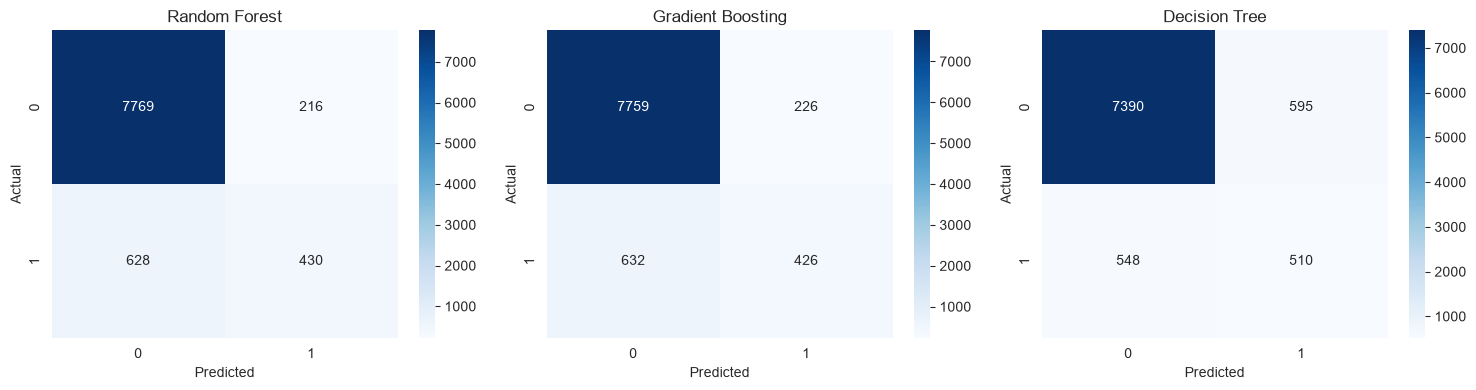

In [47]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, (name, model) in enumerate(top_3_model_objects.items()):
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)

    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i])
    axes[i].set_title(f'{name}')
    axes[i].set_xlabel('Predicted')
    axes[i].set_ylabel('Actual')

plt.tight_layout()
plt.show()

**Вопрос:** Какая модель лучше всего находит положительный класс (клиентов, которые откроют вклад)?

**Ответ:** recall

---

## ****Часть 10. Оптимизация гиперпараметров с GridSearchCV****

> 📚 **Подсказка:** GridSearchCV перебирает все комбинации гиперпараметров и выбирает лучшую с помощью кросс-валидации.

### ****10.1. Определите сетки гиперпараметров для топ-3 моделей****

In [48]:
param_grids = {
    "Logistic Regression": {
        "C": [0.1, 1, 10]
    },
    "Decision Tree": {
        "max_depth": [5, 10, None],
        "min_samples_leaf": [1, 5]
    },
    "Random Forest": {
        "n_estimators": [100, 200],
        "max_depth": [8, None],
        "min_samples_leaf": [1, 5]
    },
    "Gradient Boosting": {
        "n_estimators": [50, 100],
        "learning_rate": [0.05, 0.1],
        "max_depth": [2, 3]
    },
    "AdaBoost": {
        "n_estimators": [50, 100],
        "learning_rate": [0.1, 1]
    },
    "SVM": {
        "C": [0.5, 1, 2]
    },
    "KNN": {
        "n_neighbors": [5, 11, 21],
        "weights": ["uniform", "distance"]
    },
    "Naive Bayes": {
        "var_smoothing": [1e-9, 1e-8, 1e-7]
    }
}

print("Сетки параметров созданы")

Сетки параметров созданы


### ****10.2. Запустите GridSearchCV для каждой модели из топ-3****

In [49]:
tuning_results = {}

for name in top_3_models:
    print("\nНастройка:", name)

    model = top_3_model_objects[name]
    params = param_grids[name]

    grid = GridSearchCV(
        model,
        params,
        cv=3,
        scoring="f1",
        n_jobs=1
    )

    grid.fit(X_train_scaled, y_train)

    pred = grid.best_estimator_.predict(X_test_scaled)

    tuning_results[name] = {
        "best_params": grid.best_params_,
        "best_estimator": grid.best_estimator_,
        "test_f1": f1_score(y_test, pred),
        "test_accuracy": accuracy_score(y_test, pred)
    }

    print("Лучшие параметры:", grid.best_params_)
    print("F1:", round(tuning_results[name]["test_f1"], 4))
    print("Accuracy:", round(tuning_results[name]["test_accuracy"], 4))


Настройка: Random Forest
Лучшие параметры: {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 200}
F1: 0.5053
Accuracy: 0.9062

Настройка: Gradient Boosting
Лучшие параметры: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100}
F1: 0.4982
Accuracy: 0.9051

Настройка: Decision Tree
Лучшие параметры: {'max_depth': 10, 'min_samples_leaf': 1}
F1: 0.4778
Accuracy: 0.8987


### ****10.3. Сравните результаты ДО и ПОСЛЕ тюнинга****

In [50]:
print("=" * 70)
print("СРАВНЕНИЕ РЕЗУЛЬТАТОВ ДО И ПОСЛЕ ТЮНИНГА")
print("=" * 70)

comparison_tuning = []

for name in top_3_models:
    # Результаты до тюнинга
    before = df_comparison_extended[df_comparison_extended['model_name'] == name].iloc[0]

    # Результаты после тюнинга
    after = tuning_results.get(name, {})

    if after:
        comparison_tuning.append({
            'Model': name,
            'F1 (до)': before['f1'],
            'F1 (после)': after['test_f1'],
            'Δ F1': after['test_f1'] - before['f1'],
            'Accuracy (до)': before['accuracy'],
            'Accuracy (после)': after['test_accuracy'],
            'Δ Accuracy': after['test_accuracy'] - before['accuracy']
        })

df_tuning_comparison = pd.DataFrame(comparison_tuning)
print(df_tuning_comparison.to_string(index=False))
print("=" * 70)

СРАВНЕНИЕ РЕЗУЛЬТАТОВ ДО И ПОСЛЕ ТЮНИНГА
            Model  F1 (до)  F1 (после)     Δ F1  Accuracy (до)  Accuracy (после)  Δ Accuracy
    Random Forest 0.504695    0.505251 0.000556       0.906668          0.906226   -0.000442
Gradient Boosting 0.498246    0.498246 0.000000       0.905120          0.905120    0.000000
    Decision Tree 0.471567    0.477765 0.006198       0.873604          0.898706    0.025102


**Вопрос:** Для какой модели тюнинг дал наибольшее улучшение?

**Ответ:** 

**Вопрос:** Какие гиперпараметры оказали наибольшее влияние на качество?

**Ответ:** 

---

## ****Часть 11. Финальное сравнение и выводы****

### ****11.1. Постройте итоговую таблицу всех экспериментов****

In [51]:
# Соберите все эксперименты в одну таблицу
final_summary = []

# Baseline (только числовые признаки)
baseline_results = df_comparison.iloc[0]  # Лучшая модель на baseline
final_summary.append({
    'Эксперимент': 'Baseline (числовые признаки)',
    'Модель': baseline_results['model_name'],
    'Кол-во признаков': len(numeric_cols),
    'F1-Score': baseline_results['f1'],
    'Accuracy': baseline_results['accuracy']
})

# После Feature Engineering
extended_results = df_comparison_extended.iloc[0]
final_summary.append({
    'Эксперимент': 'Feature Engineering + One-Hot',
    'Модель': extended_results['model_name'],
    'Кол-во признаков': X_final.shape[1],
    'F1-Score': extended_results['f1'],
    'Accuracy': extended_results['accuracy']
})

# После тюнинга (лучшая модель)
best_tuned = max(tuning_results.items(), key=lambda x: x[1]['test_f1'])
final_summary.append({
    'Эксперимент': 'После GridSearchCV',
    'Модель': f"{best_tuned[0]} (tuned)",
    'Кол-во признаков': X_final.shape[1],
    'F1-Score': best_tuned[1]['test_f1'],
    'Accuracy': best_tuned[1]['test_accuracy']
})

df_final_summary = pd.DataFrame(final_summary)
print("=" * 80)
print("ИТОГОВАЯ ТАБЛИЦА ЭКСПЕРИМЕНТОВ")
print("=" * 80)
print(df_final_summary.to_string(index=False))
print("=" * 80)

ИТОГОВАЯ ТАБЛИЦА ЭКСПЕРИМЕНТОВ
                  Эксперимент                Модель  Кол-во признаков  F1-Score  Accuracy
 Baseline (числовые признаки)         Random Forest                 7  0.409257  0.892735
Feature Engineering + One-Hot         Random Forest                45  0.504695  0.906668
           После GridSearchCV Random Forest (tuned)                45  0.505251  0.906226


### ****11.2. Визуализируйте прогресс улучшения модели****

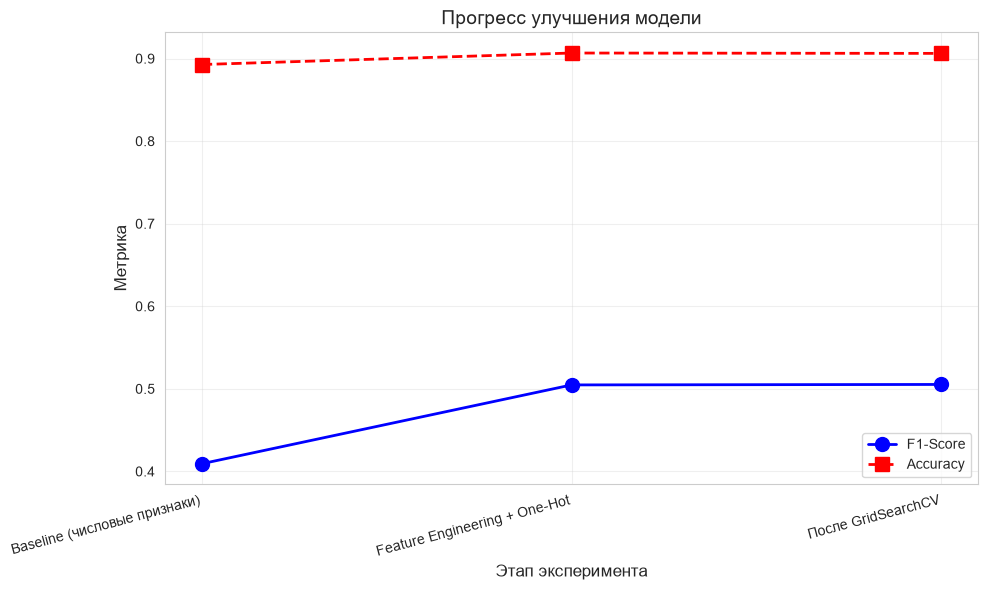


ОБЩИЙ ПРИРОСТ:
F1-Score: 0.4093 → 0.5053 (+0.0960)
Accuracy: 0.8927 → 0.9062 (+0.0135)


In [54]:
# График прогресса
plt.figure(figsize=(10, 6))

x = range(len(df_final_summary))
plt.plot(x, df_final_summary['F1-Score'], 'bo-', markersize=10, linewidth=2, label='F1-Score')
plt.plot(x, df_final_summary['Accuracy'], 'rs--', markersize=10, linewidth=2, label='Accuracy')

plt.xticks(x, df_final_summary['Эксперимент'], rotation=15, ha='right')
plt.xlabel('Этап эксперимента', fontsize=12)
plt.ylabel('Метрика', fontsize=12)
plt.title('Прогресс улучшения модели', fontsize=14)
plt.legend(fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Прирост
print(f"\nОБЩИЙ ПРИРОСТ:")
print(f"F1-Score: {df_final_summary.iloc[0]['F1-Score']:.4f} → {df_final_summary.iloc[-1]['F1-Score']:.4f} ({df_final_summary.iloc[-1]['F1-Score'] - df_final_summary.iloc[0]['F1-Score']:+.4f})")
print(f"Accuracy: {df_final_summary.iloc[0]['Accuracy']:.4f} → {df_final_summary.iloc[-1]['Accuracy']:.4f} ({df_final_summary.iloc[-1]['Accuracy'] - df_final_summary.iloc[0]['Accuracy']:+.4f})")

### ****11.3. Ответьте на итоговые вопросы****



**Вопрос 1:** Какая модель показала лучший финальный результат и почему, по вашему мнению?

**Ответ:** random forest

**Вопрос 2:** Какие признаки оказались шумовыми (ухудшали модель)?

**Ответ:** 

**Вопрос 3:** Насколько Feature Engineering улучшил результат по сравнению с baseline?

**Ответ:** F1-Score вырос с 0.4093 до 0.5047, a accuracy вырос с 0.8927 до 0.9067

**Вопрос 4:** Насколько GridSearchCV улучшил результат? Стоило ли это затраченного времени?

**Ответ:** небольшое дополнительное улучшение: F1-Score вырос с 0.5047 до 0.5053, accuracy снизился с 0.9067 до 0.9062, результаты улучшения минимальны

**Вопрос 5:** Какие гиперпараметры оказали наибольшее влияние на качество лучшей модели?

**Ответ:** 

**Вопрос 6:** Какие подтвердились из ваших гипотез?

**Ответ:** 

**Вопрос 7:** Что бы вы попробовали ещё для улучшения модели?

**Ответ:** 

## ****Бонус: Сохранение лучшей модели****

In [53]:
import joblib

# Сохраняем лучшую модель
best_model_name = best_tuned[0]
best_model = tuning_results[best_model_name]['best_estimator']

joblib.dump(best_model, 'best_bank_marketing_model.pkl')
joblib.dump(scaler, 'scaler.pkl')

print(f"Лучшая модель ({best_model_name}) сохранена в 'best_bank_marketing_model.pkl'")
print(f"Scaler сохранён в 'scaler.pkl'")

Лучшая модель (Random Forest) сохранена в 'best_bank_marketing_model.pkl'
Scaler сохранён в 'scaler.pkl'
